# Fawwar Refugee Camp – Built-up Change Analysis v2 (noise-reduced)

**What is new compared with v1**

| Noise source in v1 | Fix in v2 |
|---|---|
| The two images are slightly shifted against each other | **Automatic co-registration** (phase correlation) |
| Building edges flagged as change because of different look angles | **Positional tolerance**: a pixel only counts as new/lost if there was no built-up within `TOL_M` metres on the other date |
| Shadows (long winter shadows) flagged as lost buildings | **Shadow mask**: darkest pixels are treated as *uncertain*, not as change |
| Fields / greenhouses / trees mixed into the built-up class | **More classes** (10) + **vegetation exclusion** (ExG) + optional **supervised Random Forest** |
| Salt-and-pepper pixels | **Majority filter + morphological opening/closing** on the built-up masks |
| Thin slivers counted as change | Change patches must be **compact and ≥ `MIN_CHANGE_M2`** |
| Class flips without real spectral change | **Spectral change check**: the pixel must also change clearly in colour/texture |
| No idea how accurate the map is | **Accuracy check**: random sample points with before/after image chips |

The notebook also reports the **v1 (naive) numbers next to the v2 numbers**, so you can show in the report how much noise was removed.

Files expected in `/content/fawwar`. Files in the Colab file panel are deleted when the runtime disconnects – keep copies.

In [1]:
!pip -q install rasterio geopandas

In [2]:
import os, io, re, json, zipfile
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling, calculate_default_transform
from rasterio.features import geometry_mask
from rasterio.transform import from_origin, rowcol
from rasterio.features import shapes
from shapely.geometry import box, Point, shape
from scipy import ndimage
from skimage.exposure import match_histograms
from skimage.registration import phase_cross_correlation
from skimage.morphology import disk
from skimage.filters import threshold_otsu
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Circle
from PIL import Image

## 1. Settings
Use the **real acquisition date** of each image as the key (Esri Wayback metadata pop-up), not the Wayback release date.

In [3]:
DATA_DIR = '/content/fawwar'
IMAGES = {                                   # acquisition date : file name
    '2022-02-02': '20220202_Fawwar.tpkx',
    '2026-01-29': '20260129_Fawwar.tpkx',
}
# CAMP_FILE    = 'fawwar_camp.gpkg'   # PCBS locality boundary "Al Fawwar Camp" (LOCCODE 13502905)
CAMP_FILE    = 'fawwar_camp_boundary.gpkg'
CAMP_INDEX   = None                 # only used for .osm files
CONTROL_FILE = None                 # e.g. 'control.gpkg' (PCBS "Hadab al Fawwar", LOCCODE 13502920)
TRAIN_FILE   = None                 # optional training points for Random Forest, e.g. 'train.gpkg'

TARGET_CRS = 'EPSG:2039' # Israel TM Grid (metres)
MIN_RES    = 0.5         # working resolution (m)
BUFFER_M   = 200         # buffer ring around the camp (m)
GRID_M     = 50          # grid cell size (m)

# --- classification ---
N_CLUSTERS = 10
VEG_EXG    = 0.06

# --- noise reduction ---
COREGISTER     = True
MAX_SHIFT_M    = 15
SHADOW_PCT     = 8
CLEAN_M        = 1.0
MIN_BUILT_M2   = 20
TOL_M          = 2.0
CHANGE_OPEN_M  = 1.5
MIN_CHANGE_M2  = 30
SPECTRAL_CHECK = True

# --- accuracy check ---
N_CHECK = 20
CHIP_M  = 20

OUT_DIR = '/content/outputs_v2'
os.makedirs(OUT_DIR, exist_ok=True)
dates = sorted(IMAGES)
REF, first, last = dates[0], dates[0], dates[-1]

# Stop with a clear error if a file is missing (no silent fallback to another boundary file)
files_here = os.listdir(DATA_DIR)
print('Files found:', files_here)
needed = list(IMAGES.values()) + [CAMP_FILE] + [f for f in (CONTROL_FILE, TRAIN_FILE) if f]
missing = [f for f in needed if f not in files_here]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_DIR}: {missing}  - check spelling or upload them.')

# Quick check of the camp boundary
_camp = gpd.read_file(os.path.join(DATA_DIR, CAMP_FILE)).to_crs(TARGET_CRS)
print(f'{CAMP_FILE}: {len(_camp)} polygon(s), area = {_camp.area.sum() / 1e6:.3f} km²')
if len(_camp) > 1:
    print('WARNING: more than one polygon - they will be merged into one camp area.')

Files found: ['road_network_roads.geojson', 'fawwar_camp_boundary.gpkg', '20220202_Fawwar.tpkx', 'AI_Fawwar_refugee.osm', '20260129_Fawwar.tpkx', 'fawwar_camp.gpkg']
fawwar_camp_boundary.gpkg: 1 polygon(s), area = 0.284 km²


## 2. Convert tile packages (.tpkx) to GeoTIFF

In [4]:
WM_ORIGIN = 20037508.342787
WM_RES0 = 156543.03392804097

def tpkx_to_geotiff(tpkx_path, out_tif, level=None):
    zf = zipfile.ZipFile(tpkx_path)
    pat = re.compile(r'L(\d+)/R([0-9a-fA-F]+)C([0-9a-fA-F]+)\.bundle$')
    bundles = {}
    for n in zf.namelist():
        m = pat.search(n)
        if m:
            bundles.setdefault(int(m.group(1)), []).append((n, int(m.group(2), 16), int(m.group(3), 16)))
    if not bundles:
        raise ValueError(f'No .bundle tiles found in {tpkx_path}')
    origin_x, origin_y, tile_size, packet, res_by_level, wkid = -WM_ORIGIN, WM_ORIGIN, 256, 128, {}, 3857
    roots = [n for n in zf.namelist() if n.lower().endswith('root.json')]
    if roots:
        root = json.loads(zf.read(roots[0]))
        info = root.get('tileInfo', {})
        o = info.get('origin', {})
        origin_x, origin_y = o.get('x', origin_x), o.get('y', origin_y)
        tile_size = info.get('rows', tile_size)
        res_by_level = {l['level']: l['resolution'] for l in info.get('lods', [])}
        sr = info.get('spatialReference', {})
        wkid = sr.get('latestWkid') or sr.get('wkid') or wkid
        packet = root.get('storageInfo', {}).get('packetSize', packet)
    level = max(bundles) if level is None else level
    res = res_by_level.get(level, WM_RES0 / 2 ** level)
    tiles = {}
    for name, brow, bcol in bundles[level]:
        data = zf.read(name)
        idx = np.frombuffer(data[64:64 + 8 * packet * packet], dtype='<u8')
        for k in np.nonzero(idx >> np.uint64(40))[0]:
            off = int(idx[k] & np.uint64((1 << 40) - 1)); size = int(idx[k] >> np.uint64(40))
            tiles[(brow + k // packet, bcol + k % packet)] = data[off:off + size]
    rows = [r for r, _ in tiles]; cols = [c for _, c in tiles]
    r0, r1, c0, c1 = min(rows), max(rows), min(cols), max(cols)
    mosaic = np.zeros(((r1 - r0 + 1) * tile_size, (c1 - c0 + 1) * tile_size, 3), dtype='uint8')
    for (r, c), b in tiles.items():
        im = np.asarray(Image.open(io.BytesIO(b)).convert('RGB'))
        y, x = (r - r0) * tile_size, (c - c0) * tile_size
        mosaic[y:y + im.shape[0], x:x + im.shape[1]] = im
    crs = 'EPSG:3857' if wkid in (102100, 102113, 900913, 3857) else f'EPSG:{wkid}'
    transform = from_origin(origin_x + c0 * tile_size * res, origin_y - r0 * tile_size * res, res, res)
    with rasterio.open(out_tif, 'w', driver='GTiff', height=mosaic.shape[0], width=mosaic.shape[1], count=3,
                       dtype='uint8', crs=crs, transform=transform, nodata=0, compress='deflate', tiled=True) as dst:
        dst.write(np.moveaxis(mosaic, -1, 0))
    print(f'{os.path.basename(tpkx_path)}: level {level}, {len(tiles)} tiles, {res:.2f} m/px -> {out_tif}')
    return out_tif

TIFS = {}
for d in dates:
    p = os.path.join(DATA_DIR, IMAGES[d])
    TIFS[d] = tpkx_to_geotiff(p, os.path.join(OUT_DIR, f'image_{d}.tif')) if p.lower().endswith('.tpkx') else p

20220202_Fawwar.tpkx: level 17, 54 tiles, 1.19 m/px -> /content/outputs_v2/image_2022-02-02.tif
20260129_Fawwar.tpkx: level 18, 204 tiles, 0.60 m/px -> /content/outputs_v2/image_2026-01-29.tif


## 3. Camp boundary
The red outline is the polygon used as the camp. If it is wrong, set `CAMP_INDEX` in step 1 and re-run from step 1.

Camp polygon area: 0.284 km²


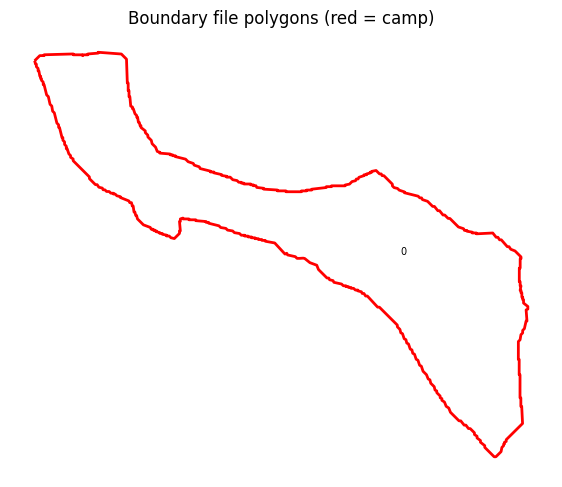

In [5]:
def read_polys(path):
    return gpd.read_file(path, layer='multipolygons') if path.lower().endswith('.osm') else gpd.read_file(path)

def dissolve(gdf):
    return gdf.union_all() if hasattr(gdf, 'union_all') else gdf.unary_union

polys = read_polys(os.path.join(DATA_DIR, CAMP_FILE)).to_crs(TARGET_CRS)
polys['area_km2'] = polys.area / 1e6
if CAMP_FILE.lower().endswith('.osm'):
    if 'building' in polys:
        polys = polys[polys['building'].isna()]
    show_cols = [c for c in ['name', 'landuse', 'boundary', 'other_tags', 'area_km2'] if c in polys]
    display(polys[show_cols].sort_values('area_km2', ascending=False).round(3))
    if CAMP_INDEX is not None:
        camp_idx = CAMP_INDEX
    else:
        text = polys[[c for c in ['name', 'other_tags'] if c in polys]].astype(str).agg(' '.join, axis=1).str.lower()
        hits = polys[text.str.contains('refugee|camp|fawwar|فوار|مخيم')]
        if len(hits):
            camp_idx = hits['area_km2'].idxmax()
        elif 'landuse' in polys and (polys['landuse'] == 'residential').any():
            camp_idx = polys[polys['landuse'] == 'residential']['area_km2'].idxmax()
        else:
            camp_idx = polys['area_km2'].idxmax()
    camp_geom = polys.loc[camp_idx, 'geometry']
    print(f'Using polygon index {camp_idx} as camp boundary')
else:
    camp_geom = dissolve(polys)

buffer_geom = camp_geom.buffer(BUFFER_M)
ring_geom = buffer_geom.difference(camp_geom)
areas = {'camp': camp_geom, 'ring': ring_geom}
extent_geoms = [buffer_geom]
if CONTROL_FILE:
    areas['control'] = dissolve(read_polys(os.path.join(DATA_DIR, CONTROL_FILE)).to_crs(TARGET_CRS))
    extent_geoms.append(areas['control'])
AREA_NAMES = {'camp': 'Camp', 'ring': f'{BUFFER_M} m buffer ring', 'control': 'Control area'}
print(f'Camp polygon area: {camp_geom.area / 1e6:.3f} km²')

fig, ax = plt.subplots(figsize=(7, 7))
polys.boundary.plot(ax=ax, color='grey', lw=0.6)
for i, g in polys.geometry.items():
    ax.annotate(str(i), g.representative_point().coords[0], fontsize=7, ha='center')
gpd.GeoSeries([camp_geom]).boundary.plot(ax=ax, color='red', lw=2)
ax.set_title('Boundary file polygons (red = camp)'); ax.set_axis_off(); plt.show()

## 4. Common grid

In [6]:
# Use the COARSEST image resolution, so the sharper image is averaged down instead of the blurrier one being "invented" up
native = {}
for d in dates:
    with rasterio.open(TIFS[d]) as src:
        t, _, _ = calculate_default_transform(src.crs, TARGET_CRS, src.width, src.height, *src.bounds)
        native[d] = abs(t.a)
    print(f'{d}: native ground resolution {native[d]:.2f} m')
RES = max(max(native.values()), MIN_RES)
if max(native.values()) / min(native.values()) > 1.4:
    print('WARNING: the images have very different resolutions - the sharper one is resampled to the coarser one.')
minx, miny, maxx, maxy = gpd.GeoSeries(extent_geoms).total_bounds
minx -= 30; miny -= 30; maxx += 30; maxy += 30
W = int(np.ceil((maxx - minx) / RES)); H = int(np.ceil((maxy - miny) / RES))
GT = from_origin(minx, maxy, RES, RES)
EXTENT = (minx, minx + W * RES, maxy - H * RES, maxy)
PIX = RES ** 2
print(f'Resolution {RES:.2f} m, grid {W} x {H} px')

def load(path):
    out = np.full((3, H, W), np.nan, dtype='float32')
    with rasterio.open(path) as src:
        for b in range(3):
            reproject(rasterio.band(src, min(b + 1, src.count)), out[b],
                      src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                      dst_transform=GT, dst_crs=TARGET_CRS, dst_nodata=np.nan, resampling=Resampling.average)
    img = np.moveaxis(out, 0, -1)
    return img, ~np.isnan(img).any(-1) & (np.nansum(img, -1) > 0)

def mask_of(geom):
    return geometry_mask([geom], out_shape=(H, W), transform=GT, invert=True)

masks = {k: mask_of(g) for k, g in areas.items()}
analysis = mask_of(buffer_geom)
if CONTROL_FILE:
    analysis |= masks['control']

imgs, valids = {}, {}
for d in dates:
    imgs[d], valids[d] = load(TIFS[d])

def update_common():
    c = analysis.copy()
    for d in dates:
        c &= valids[d]
    return c
common = update_common()
print('Valid pixels:', int(common.sum()))

2022-02-02: native ground resolution 1.02 m
2026-01-29: native ground resolution 0.51 m
Resolution 1.02 m, grid 1564 x 1364 px
Valid pixels: 1018529


## 5. Co-registration
Estimates the shift between the images from edge structure (robust to illumination) and moves the later image(s) onto the reference image. A shift of ~1–3 m is typical for Wayback imagery.

Note: this corrects a **global shift** only. Tall buildings still lean differently when the two images were taken from different angles (parallax) – the positional tolerance in step 9 handles that.

In [7]:
def edges(img):
    br = np.nan_to_num(np.nanmean(img, -1), nan=float(np.nanmean(img)))
    return np.hypot(ndimage.sobel(br, 0), ndimage.sobel(br, 1))

if COREGISTER:
    rws, cls = np.where(common)
    r0, r1, c0, c1 = rws.min(), rws.max() + 1, cls.min(), cls.max() + 1
    ref_e = edges(imgs[REF][r0:r1, c0:c1])
    for d in dates:
        if d == REF:
            continue
        shift, err, _ = phase_cross_correlation(ref_e, edges(imgs[d][r0:r1, c0:c1]), upsample_factor=10)
        dy, dx = shift
        dist = np.hypot(dy, dx) * RES
        print(f'{d}: shift dy={dy * RES:+.2f} m, dx={dx * RES:+.2f} m (total {dist:.2f} m)')
        if dist > MAX_SHIFT_M:
            print('  -> larger than MAX_SHIFT_M, not applied')
            continue
        for b in range(3):
            imgs[d][..., b] = ndimage.shift(imgs[d][..., b], (dy, dx), order=1, mode='constant', cval=np.nan)
        valids[d] = ndimage.shift(valids[d].astype('float32'), (dy, dx), order=0, mode='constant', cval=0) > 0.5
        valids[d] &= ~np.isnan(imgs[d]).any(-1)
    common = update_common()
print('Valid pixels after co-registration:', int(common.sum()))

/tmp/ipykernel_2238/2422700451.py:2: RuntimeWarning: Mean of empty slice
  br = np.nan_to_num(np.nanmean(img, -1), nan=float(np.nanmean(img)))


2026-01-29: shift dy=-0.51 m, dx=+1.22 m (total 1.32 m)
Valid pixels after co-registration: 1018520


## 6. Contrast stretch + radiometric harmonisation

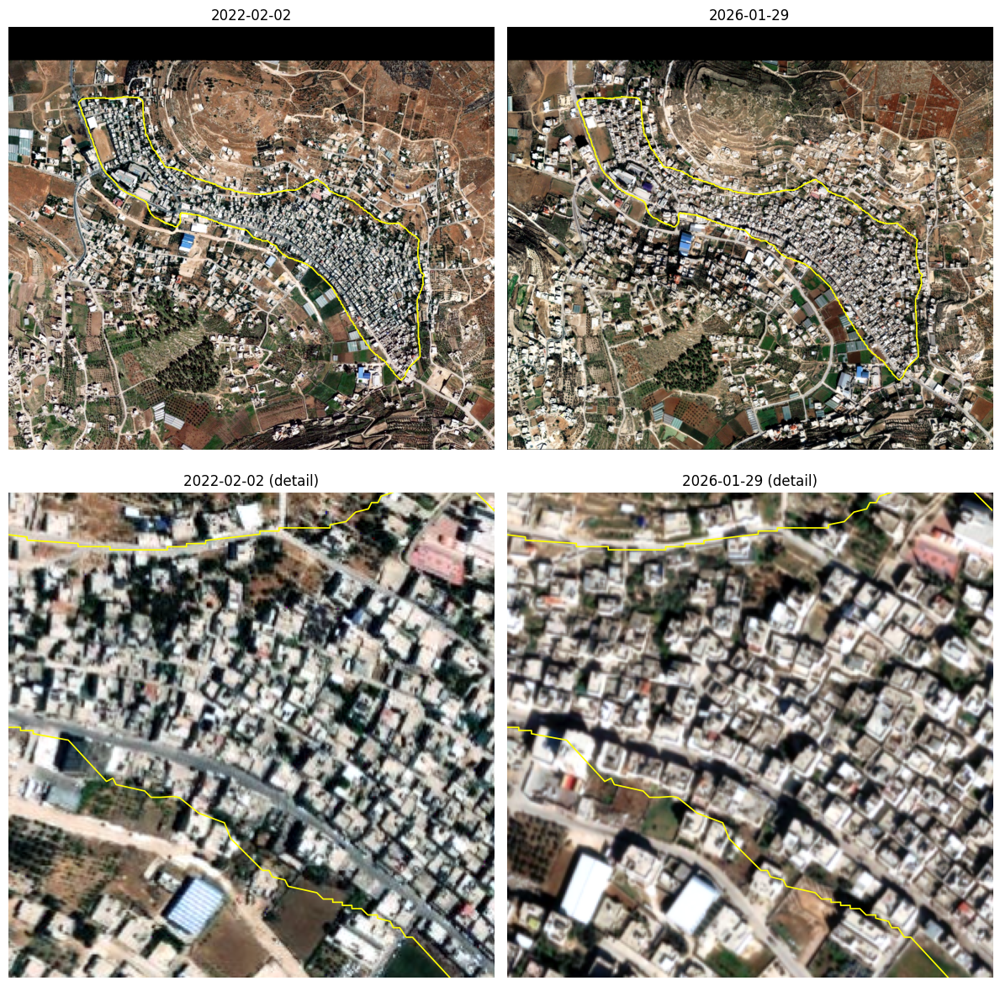

In [8]:
for d in dates:
    for b in range(3):
        v = imgs[d][..., b][common]
        lo, hi = np.percentile(v, [1, 99])
        imgs[d][..., b] = np.clip((imgs[d][..., b] - lo) / (hi - lo + 1e-9), 0, 1)
for d in dates:
    if d != REF:
        for b in range(3):
            imgs[d][..., b][common] = match_histograms(imgs[d][..., b][common], imgs[REF][..., b][common])

cx, cy = camp_geom.centroid.x, camp_geom.centroid.y
ZOOM = (cx - 150, cx + 150, cy - 150, cy + 150)        # 300 m x 300 m detail window

def show_rgb(ax, img, title, dim=1.0, zoom=False):
    ax.imshow(np.nan_to_num(img) * dim, extent=EXTENT)
    gpd.GeoSeries([camp_geom]).boundary.plot(ax=ax, color='yellow', lw=1.2)
    if zoom:
        ax.set_xlim(ZOOM[0], ZOOM[1]); ax.set_ylim(ZOOM[2], ZOOM[3])
    ax.set_title(title); ax.set_axis_off()

fig, axes = plt.subplots(2, len(dates), figsize=(6 * len(dates), 12))
for i, d in enumerate(dates):
    show_rgb(axes[0, i], imgs[d], d)
    show_rgb(axes[1, i], imgs[d], f'{d} (detail)', zoom=True)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/01_rgb_aligned.png', dpi=200); plt.show()

## 7. Features and classification
**Default: K-means** with 10 classes on all dates together, then you choose the built-up classes (step 8).

**Optional, more accurate: Random Forest.** In QGIS create a point layer `train.gpkg` with an integer field `built` (1 = roof / paved, 0 = anything else). Put ~40 points of each kind **only on places that did NOT change** between the dates (so one label is valid for both images), include greenhouses, bright bare limestone, fields and trees as 0. Upload it and set `TRAIN_FILE = 'train.gpkg'`.

In [9]:
def features(img):
    R, G, B = img[..., 0], img[..., 1], img[..., 2]
    br = (R + G + B) / 3
    exg = 2 * G - R - B
    mx, mn = img.max(-1), img.min(-1)
    sat = (mx - mn) / (mx + 1e-6)
    b0 = np.nan_to_num(br)
    tex = []
    for w in (3, 7):                                     # fine and coarse texture
        m1 = ndimage.uniform_filter(b0, w); m2 = ndimage.uniform_filter(b0 ** 2, w)
        tex.append(np.sqrt(np.clip(m2 - m1 ** 2, 0, None)))
    return np.stack([R, G, B, br, exg, sat, *tex], -1).astype('float32')

FEAT_NAMES = ['R', 'G', 'B', 'brightness', 'ExG', 'saturation', 'texture_3', 'texture_7']
feats = {d: features(imgs[d]) for d in dates}

rng = np.random.default_rng(0)
sample = np.vstack([feats[d][common][rng.choice(int(common.sum()), min(60000, int(common.sum())), replace=False)]
                    for d in dates])
scaler = StandardScaler().fit(sample)

# Spectral change magnitude (used in step 9)
z = {d: np.zeros((H, W, len(FEAT_NAMES)), 'float32') for d in dates}
for d in dates:
    z[d][common] = scaler.transform(feats[d][common])
mag = ndimage.uniform_filter(np.linalg.norm(z[last] - z[first], axis=-1), 3)
MAG_T = threshold_otsu(mag[common])
print(f'Spectral change threshold (Otsu): {MAG_T:.2f}')

raw_built, labels = {}, {}
if TRAIN_FILE:
    tr = gpd.read_file(os.path.join(DATA_DIR, TRAIN_FILE)).to_crs(TARGET_CRS)
    rr_, cc_ = map(np.array, rowcol(GT, tr.geometry.x.values, tr.geometry.y.values))
    ok = (rr_ >= 0) & (rr_ < H) & (cc_ >= 0) & (cc_ < W)
    rr_, cc_, yv = rr_[ok], cc_[ok], tr['built'].values[ok].astype(int)
    X, y = [], []
    for d in dates:
        good = common[rr_, cc_]
        X.append(feats[d][rr_[good], cc_[good]]); y.append(yv[good])
    rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=0)
    rf.fit(np.vstack(X), np.concatenate(y))
    print(f'Random Forest trained on {sum(len(v) for v in y)} samples; out-of-bag style check below is visual')
    for d in dates:
        p = np.zeros((H, W), 'float32')
        p[common] = rf.predict_proba(feats[d][common])[:, 1]
        raw_built[d] = p > 0.5
else:
    km = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=0).fit(scaler.transform(sample))
    for d in dates:
        lab = np.full((H, W), -1, dtype=int)
        lab[common] = km.predict(scaler.transform(feats[d][common]))
        labels[d] = lab
    summary = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEAT_NAMES)
    zc = (summary - summary.mean()) / summary.std()
    summary['built_score'] = zc['brightness'] + zc['texture_3'] - zc['ExG']
    summary = summary.sort_values('built_score', ascending=False)
    display(summary.round(3))

Spectral change threshold (Otsu): 3.11


,R,G,B,brightness,ExG,saturation,texture_3,texture_7,built_score
1,0.556,0.541,0.520,0.539,0.006,0.107,0.197,0.250,2.907
4,0.826,0.818,0.791,0.812,0.018,0.068,0.116,0.213,2.195
2,0.884,0.846,0.804,0.845,0.004,0.100,0.038,0.101,1.149
5,0.627,0.571,0.512,0.570,0.003,0.191,0.081,0.137,0.950
6,0.272,0.252,0.234,0.253,-0.001,0.208,0.137,0.220,0.905
3,0.532,0.421,0.340,0.431,-0.029,0.377,0.036,0.066,0.223
8,0.363,0.350,0.290,0.334,0.047,0.233,0.055,0.099,-1.205
0,0.130,0.126,0.109,0.122,0.012,0.281,0.052,0.115,-1.368
9,0.064,0.051,0.043,0.053,-0.004,0.792,0.047,0.123,-1.409
7,0.167,0.244,0.156,0.189,0.165,0.440,0.032,0.064,-4.348


## 8. ⚠️ Choose the built-up classes (K-means only)
Look at the **detail panels** (bottom). Include classes that are **roofs** (often several: bright roofs, grey concrete roofs, roofs with water tanks) and **paved roads/yards** if you want them. Exclude classes that are **greenhouses, fields, trees, bare limestone, shadows**.
Edit `BUILT_CLUSTERS`, then re-run this cell and all cells below.

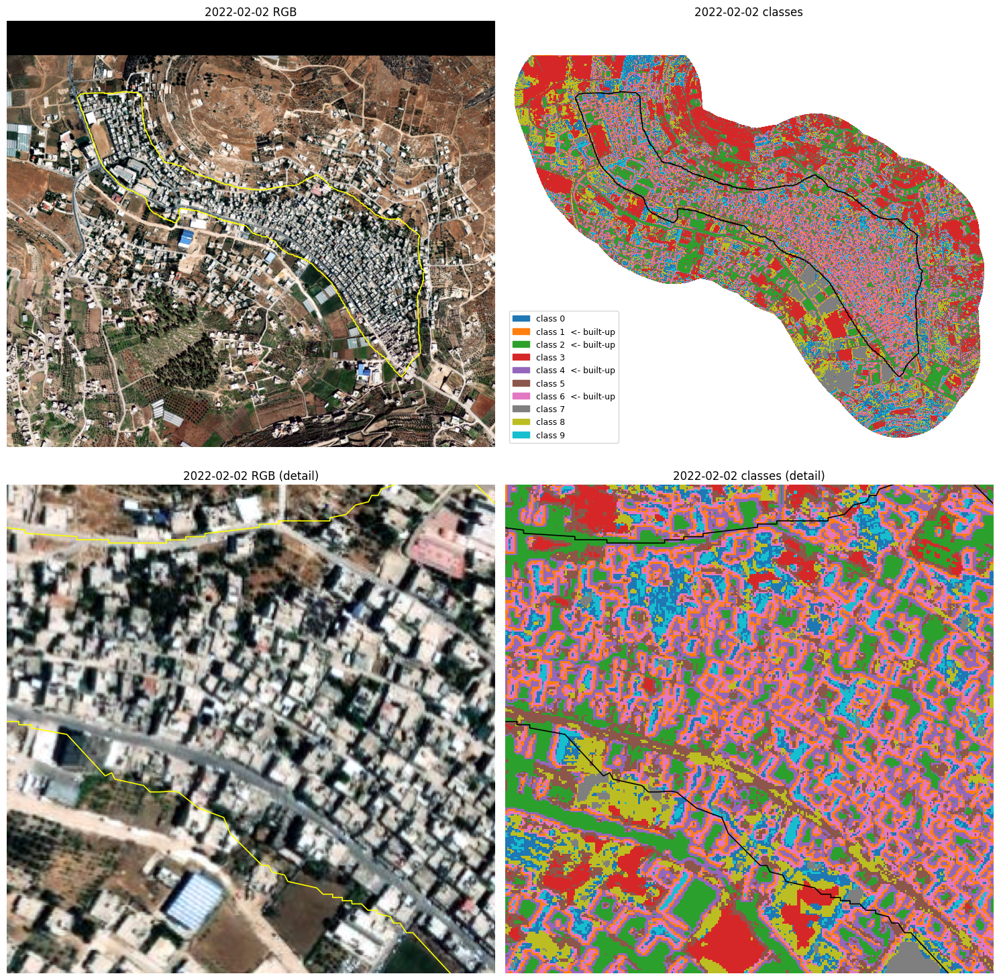

In [10]:
# BUILT_CLUSTERS = list(summary.index[:3]) if not TRAIN_FILE else []   # <- edit, e.g. [1, 4, 7]
BUILT_CLUSTERS = [1, 2, 4, 6]

if not TRAIN_FILE:
    cmap = ListedColormap((plt.cm.tab10.colors if N_CLUSTERS <= 10 else plt.cm.tab20.colors)[:N_CLUSTERS])
    fig, axes = plt.subplots(2, 2, figsize=(15, 15))
    for row, zoom in enumerate([False, True]):
        show_rgb(axes[row, 0], imgs[REF], f'{REF} RGB' + (' (detail)' if zoom else ''), zoom=zoom)
        ax = axes[row, 1]
        ax.imshow(np.ma.masked_less(labels[REF], 0), cmap=cmap, vmin=-0.5, vmax=N_CLUSTERS - 0.5,
                  extent=EXTENT, interpolation='nearest')
        gpd.GeoSeries([camp_geom]).boundary.plot(ax=ax, color='black', lw=1.2)
        if zoom:
            ax.set_xlim(ZOOM[0], ZOOM[1]); ax.set_ylim(ZOOM[2], ZOOM[3])
        ax.set_title(f'{REF} classes' + (' (detail)' if zoom else '')); ax.set_axis_off()
    axes[0, 1].legend(handles=[Patch(color=cmap(i), label=f'class {i}' + ('  <- built-up' if i in BUILT_CLUSTERS else ''))
                               for i in range(N_CLUSTERS)], loc='lower left', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/02_classes_{REF}.png', dpi=200); plt.show()
    raw_built = {d: np.isin(labels[d], BUILT_CLUSTERS) & common for d in dates}

A: [1, 2, 4, 6]: built-up = 64.4 % of the camp, 34.4 % of the buffer ring
B: [2, 4, 6]: built-up = 48.0 % of the camp, 28.6 % of the buffer ring


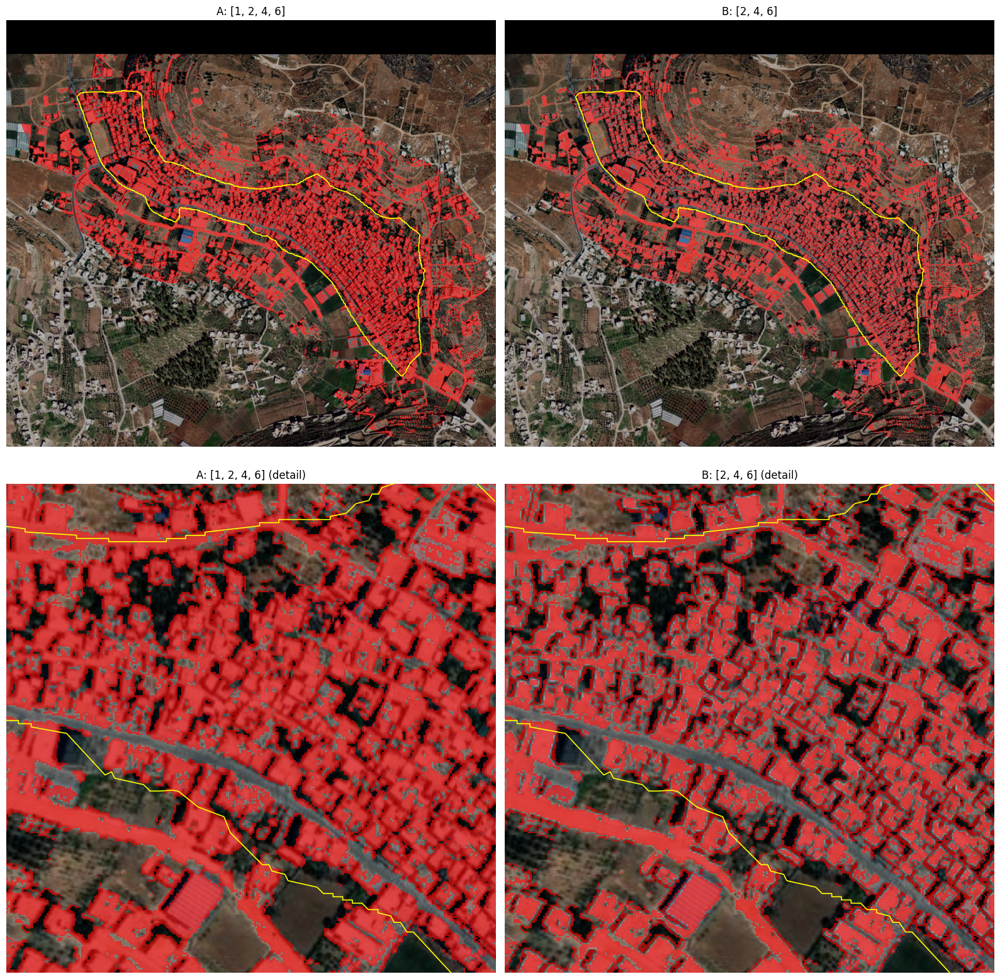

In [11]:
# 怎么看：

# 上排全图：看营地外围的温室、田地、裸地有没有大片变红。红色应该主要集中在房子上
# 下排放大图：看屋顶是不是基本都被盖住了，房子之间的阴影和路有没有被误盖
# 打印的百分比：营地内的建成区占比应该比较合理（你看影像估计一下，密集区大约一半是房子，整个范围大概 20–35%）
options = {'A: [1, 2, 4, 6]': [1, 2, 4, 6], 'B: [2, 4, 6]': [2, 4, 6]}
cm = masks['camp'] & common
fig, axes = plt.subplots(2, len(options), figsize=(8 * len(options), 16))
for col, (name, cls) in enumerate(options.items()):
    m = np.isin(labels[REF], cls) & common
    for row, zoom in enumerate([False, True]):
        ax = axes[row, col]
        show_rgb(ax, imgs[REF], f'{name}' + (' (detail)' if zoom else ''), dim=0.7, zoom=zoom)
        ax.imshow(np.ma.masked_where(~m, m), cmap=ListedColormap(['red']),
                  extent=EXTENT, interpolation='nearest', alpha=0.6)
    print(f'{name}: built-up = {100 * m[cm].mean():.1f} % of the camp, '
          f'{100 * m[masks["ring"] & common].mean():.1f} % of the buffer ring')
plt.tight_layout(); plt.show()

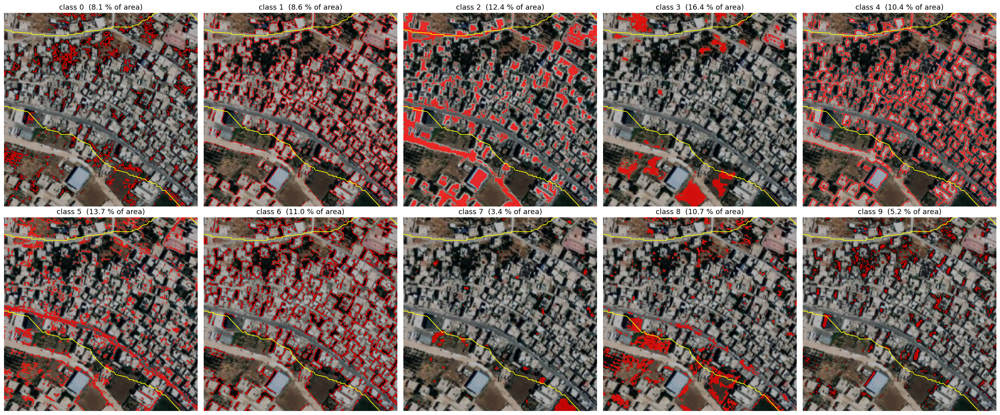

,brightness,ExG,saturation,texture_3,built_score
0,0.122,0.012,0.281,0.052,-1.368
1,0.539,0.006,0.107,0.197,2.907
2,0.845,0.004,0.100,0.038,1.149
3,0.431,-0.029,0.377,0.036,0.223
4,0.812,0.018,0.068,0.116,2.195
5,0.570,0.003,0.191,0.081,0.950
6,0.253,-0.001,0.208,0.137,0.905
7,0.189,0.165,0.440,0.032,-4.348
8,0.334,0.047,0.233,0.055,-1.205
9,0.053,-0.004,0.792,0.047,-1.409


In [12]:
# 这个代码是为了看各个分类的区域 以确定选择哪几个作为build up
fig, axes = plt.subplots(2, 5, figsize=(25, 10.5))
for c, ax in enumerate(axes.ravel()):
    show_rgb(ax, imgs[REF], '', dim=0.7, zoom=True)
    ax.imshow(np.ma.masked_where(labels[REF] != c, labels[REF]),
              cmap=ListedColormap(['red']), extent=EXTENT, interpolation='nearest', alpha=0.75)
    share = 100 * (labels[REF][common] == c).mean()
    ax.set_title(f'class {c}  ({share:.1f} % of area)', fontsize=13)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/02d_each_class.png', dpi=150); plt.show()

# Mean features of each class (brightness, greenness, texture)
display(summary[['brightness', 'ExG', 'saturation', 'texture_3', 'built_score']].sort_index().round(3))

Columns in the road file: ['patch_id', 'osm_id', 'highway', 'name', 'surface', 'oneway', 'length_m', 'group', 'class_id', 'class_name', 'cx', 'cy', 'pipeline', 'period', 'geometry']
Road type taken from column "highway":
road_type
residential     93
track           20
secondary       11
trunk            7
footway          7
service          5
unclassified     1
pedestrian       1

145 road segments; road strips cover 11.6 % of the analysis area
2022-02-02: 17.2 % of built-up pixels inside the camp were on roads -> removed
2026-01-29: 18.9 % of built-up pixels inside the camp were on roads -> removed


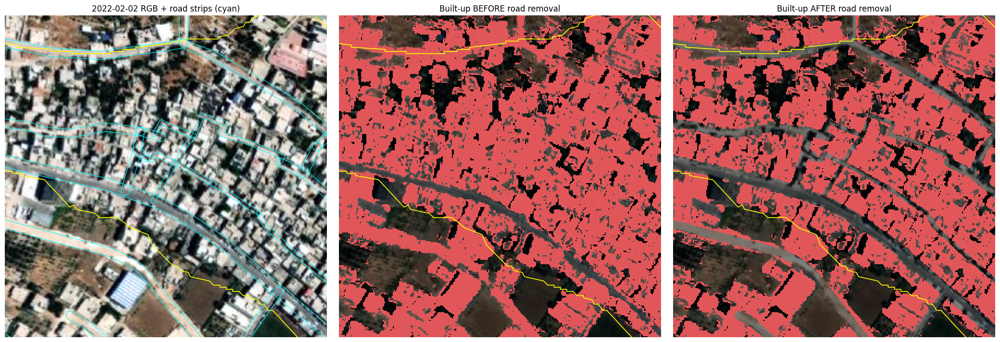

In [13]:
# ---- Remove roads from the built-up masks ----
ROAD_PATH    = '/content/fawwar/road_network_roads.geojson'
ROAD_EXTRA_M = 1.0     # extra margin on each side of the road (m)
DEFAULT_W    = 6       # road width (m) used when the road type is unknown
WIDTH = {              # assumed full road width (m) by OSM road type
    'motorway': 14, 'trunk': 12, 'primary': 10, 'secondary': 9, 'tertiary': 8,
    'unclassified': 6, 'residential': 6, 'living_street': 5, 'road': 6,
    'service': 4, 'track': 4, 'footway': 2, 'path': 2, 'steps': 2, 'pedestrian': 4,
}

roads = gpd.read_file(ROAD_PATH)
print('Columns in the road file:', list(roads.columns))
roads = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].to_crs(TARGET_CRS)

# Find the column that holds the road type (name differs between data sources)
type_col = next((c for c in ['highway', 'fclass', 'road_type', 'type', 'class'] if c in roads.columns), None)
if type_col:
    roads['road_type'] = roads[type_col].astype(str)
    roads['width_m'] = roads['road_type'].map(WIDTH).fillna(DEFAULT_W)
    print(f'Road type taken from column "{type_col}":')
    print(roads['road_type'].value_counts().to_string())
else:
    roads['width_m'] = DEFAULT_W
    print(f'No road-type column found - all roads get {DEFAULT_W} m width')

# Lines -> strips -> raster mask
road_poly = roads.geometry.buffer(roads['width_m'] / 2 + ROAD_EXTRA_M)
road_mask = geometry_mask(list(road_poly), out_shape=(H, W), transform=GT, invert=True) & common
print(f'\n{len(roads)} road segments; road strips cover {100 * road_mask[common].mean():.1f} % of the analysis area')

# How much of the "built-up" was actually road
cm = masks['camp'] & common
for d in dates:
    share = 100 * (raw_built[d] & road_mask)[cm].sum() / max(raw_built[d][cm].sum(), 1)
    print(f'{d}: {share:.1f} % of built-up pixels inside the camp were on roads -> removed')

# Remove road pixels from the built-up masks of both dates
raw_built_with_roads = {d: raw_built[d].copy() for d in dates}
raw_built = {d: raw_built[d] & ~road_mask for d in dates}

# Visual check (detail window)
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
show_rgb(axes[0], imgs[REF], f'{REF} RGB + road strips (cyan)', zoom=True)
gpd.GeoSeries(road_poly).boundary.plot(ax=axes[0], color='cyan', lw=0.8)
for ax, m, t in [(axes[1], raw_built_with_roads[REF], 'Built-up BEFORE road removal'),
                 (axes[2], raw_built[REF], 'Built-up AFTER road removal')]:
    show_rgb(ax, imgs[REF], t, dim=0.5, zoom=True)
    ax.imshow(np.ma.masked_where(~m, m), cmap=ListedColormap(['#e15759']),
              extent=EXTENT, interpolation='nearest')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/02c_road_mask.png', dpi=200); plt.show()

download road data

In [14]:
# !pip install pygeovision["geo"] --quiet

In [15]:
# from pygeovision import PyGeoVision

# client = PyGeoVision()
# # box = (-0.15, 51.47, -0.10, 51.52)
# camp = gpd.read_file('/content/fawwar/fawwar_camp.gpkg')
# box = tuple(camp.to_crs('EPSG:2039').buffer(300).to_crs('EPSG:4326').total_bounds.round(5))
# print('box =', box)

# # buildings = client.pipeline("building_footprints", bbox=box, source="microsoft", output_dir="out/bld_ms")
# roads = client.pipeline("road_network", bbox=box, output_dir="out/roads")
# print(roads.stats["total_length_km"])

In [16]:
# # ---- Why was each v1 change pixel removed in v2? ----
# REASONS = {
#     1: ('Vegetation (ExG)',              '#59a14f'),
#     2: ('Speckle removed by mask cleaning', '#bab0ac'),
#     3: ('Edge shift (within TOL_M)',     '#b07aa1'),
#     4: ('Shadow',                        '#4d4d4d'),
#     5: ('No clear spectral change',      '#76b7b2'),
#     6: ('Too thin / too small patch',    '#edc948'),
#     7: ('KEPT as real change (v2)',      '#e15759'),
# }
# tol_se = disk(px(TOL_M))

# def attribute(kind):
#     if kind == 'new':
#         naive, d_built, b_yes, b_no, final = naive_new, last, b1, b0, new
#     else:
#         naive, d_built, b_yes, b_no, final = naive_lost, first, b0, b1, lost
#     reason = np.zeros((H, W), 'uint8')
#     rem = naive.copy()
#     def take(mask, code):
#         nonlocal rem
#         m = rem & mask
#         reason[m] = code
#         rem &= ~m
#     take(feats[d_built][..., 4] > VEG_EXG, 1)                    # vegetation
#     take(~(b_yes & ~b_no), 2)                                     # disappeared after mask cleaning
#     take(~(b_yes & ~ndimage.binary_dilation(b_no, tol_se)), 3)    # only a small positional shift
#     take(uncertain, 4)                                            # shadow on either date
#     take(~sig, 5)                                                 # colour/texture did not really change
#     take(~final, 6)                                               # removed by opening / minimum size
#     reason[final] = 7                                             # what v2 keeps
#     return reason

# reasons = {k: attribute(k) for k in ('new', 'lost')}

# # Table: how much area each reason removed (m²), camp + buffer
# rows = []
# for k, r in reasons.items():
#     for code, (name, _) in REASONS.items():
#         rows.append({'change': k, 'reason': name, 'area_m2': ((r == code) & common).sum() * PIX})
# tab = pd.DataFrame(rows).pivot(index='reason', columns='change', values='area_m2').loc[[v[0] for v in REASONS.values()]]
# tab['share_of_v1_new_%'] = 100 * tab['new'] / max(naive_new.sum() * PIX, 1)
# tab['share_of_v1_lost_%'] = 100 * tab['lost'] / max(naive_lost.sum() * PIX, 1)
# display(tab.round(1))
# tab.to_csv(f'{OUT_DIR}/noise_reasons.csv')

# # Maps: full area + detail window, for new and lost
# rcmap = ListedColormap([v[1] for v in REASONS.values()])
# fig, axes = plt.subplots(2, 2, figsize=(16, 16))
# for row, k in enumerate(['new', 'lost']):
#     for col, zoom in enumerate([False, True]):
#         ax = axes[row, col]
#         show_rgb(ax, imgs[last if k == 'new' else first],
#                  f'v1 "{k}" pixels coloured by why they were removed' + (' (detail)' if zoom else ''),
#                  dim=0.55, zoom=zoom)
#         r = reasons[k]
#         ax.imshow(np.ma.masked_equal(r, 0), cmap=rcmap, vmin=0.5, vmax=7.5,
#                   extent=EXTENT, interpolation='nearest')
# axes[0, 0].legend(handles=[Patch(color=c, label=n) for n, c in REASONS.values()],
#                   loc='lower left', fontsize=9, framealpha=0.9)
# plt.tight_layout(); plt.savefig(f'{OUT_DIR}/08_noise_reasons_map.png', dpi=200); plt.show()

# # Bar chart
# fig, ax = plt.subplots(figsize=(9, 4.5))
# y = np.arange(len(tab)); h = 0.38
# ax.barh(y - h / 2, tab['new'] / 1000, h, color='#f28e2b', label='v1 new')
# ax.barh(y + h / 2, tab['lost'] / 1000, h, color='#4e79a7', label='v1 lost')
# ax.set_yticks(y); ax.set_yticklabels(tab.index); ax.invert_yaxis()
# ax.set_xlabel('Area (1,000 m²)'); ax.set_title('Where the v1 change went: removed as noise vs kept')
# ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
# plt.tight_layout(); plt.savefig(f'{OUT_DIR}/09_noise_reasons_bar.png', dpi=200); plt.show()

# # Side-by-side in the detail window: image 2022 | image 2026 | v1 change | v2 change
# v1_change = np.full((H, W), 255, 'uint8'); v1_change[common] = 0
# v1_change[naive_new] = 2; v1_change[naive_lost] = 3
# ccmap = ListedColormap(['#00000000', '#bdbdbd', '#f28e2b', '#2b6cb0'])
# fig, axes = plt.subplots(1, 4, figsize=(24, 6.5))
# show_rgb(axes[0], imgs[first], f'{first}', zoom=True)
# show_rgb(axes[1], imgs[last], f'{last}', zoom=True)
# for ax, ch, t in [(axes[2], v1_change, 'v1 naive change'), (axes[3], change, 'v2 noise-reduced change')]:
#     show_rgb(ax, imgs[last], t + ' (detail)', dim=0.55, zoom=True)
#     ax.imshow(np.ma.masked_where((ch == 255) | (ch < 2), ch), cmap=ccmap, vmin=-0.5, vmax=3.5,
#               extent=EXTENT, interpolation='nearest')
# axes[3].legend(handles=[Patch(color='#f28e2b', label='New'), Patch(color='#2b6cb0', label='Lost')], loc='lower left')
# plt.tight_layout(); plt.savefig(f'{OUT_DIR}/10_v1_vs_v2_detail.png', dpi=200); plt.show()

## 9. Clean built-up masks and detect change robustly
1. Vegetation (ExG > `VEG_EXG`) is never built-up
2. 3×3 majority filter, then morphological closing (fills small gaps in roofs) and opening (removes specks), then small patches removed
3. **new** = built-up on the later date with **no** built-up within `TOL_M` on the earlier date (and vice versa for **lost**)
4. Shadow pixels on either date are excluded from change
5. Optional spectral check: colour/texture must also change clearly
6. Change patches must be compact (opening with `CHANGE_OPEN_M`) and ≥ `MIN_CHANGE_M2`

In [17]:
raw_built = {d: np.isin(labels[d], BUILT_CLUSTERS) & common & ~road_mask for d in dates}
def px(m):
    return max(1, int(round(m / RES)))

def remove_small(mask, min_m2):
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = np.bincount(lab.ravel())
    keep = sizes >= max(1, int(min_m2 / PIX)); keep[0] = False
    return keep[lab]

se_clean = disk(px(CLEAN_M))
built, shadow = {}, {}
for d in dates:
    br = imgs[d].mean(-1)
    shadow[d] = common & (br <= np.nanpercentile(br[common], SHADOW_PCT))
    m = raw_built[d] & common & ~(feats[d][..., 4] > VEG_EXG)
    m = ndimage.median_filter(m.astype('uint8'), size=3).astype(bool)
    m = ndimage.binary_closing(m, se_clean)
    m = ndimage.binary_opening(m, se_clean)
    built[d] = remove_small(m, MIN_BUILT_M2) & common

tol = disk(px(TOL_M))
b0, b1 = built[first], built[last]
uncertain = shadow[first] | shadow[last]
sig = (mag > MAG_T) if SPECTRAL_CHECK else np.ones((H, W), bool)

def filt(m):
    m = m & sig & ~uncertain & common
    m = ndimage.binary_opening(m, disk(px(CHANGE_OPEN_M)))
    return remove_small(m, MIN_CHANGE_M2)

new = filt(b1 & ~ndimage.binary_dilation(b0, tol))
lost = filt(b0 & ~ndimage.binary_dilation(b1, tol))

# v1-style naive change for comparison
naive_new = raw_built[last] & ~raw_built[first] & common
naive_lost = raw_built[first] & ~raw_built[last] & common

change = np.full((H, W), 255, 'uint8')
change[common] = 0                                # not built-up
change[common & (b0 | b1)] = 1                    # built-up, no confident change
change[new] = 2                                   # new built-up
change[lost] = 3                                  # lost built-up (candidate)
print('Pixels excluded as shadow (either date): %.1f %%' % (100 * uncertain[common].mean()))

Pixels excluded as shadow (either date): 13.8 %


## 10. Statistics: v1 (naive) vs v2 (noise-reduced)

In [18]:
# 原先的分析
# rows = []
# for k, m in masks.items():
#     mm = m & common
#     a0, a1 = b0[mm].sum() * PIX, b1[mm].sum() * PIX
#     rows.append({
#         'area': AREA_NAMES[k],
#         'area_m2': mm.sum() * PIX,
#         f'built_{first}_m2': a0, f'built_{first}_pct': 100 * b0[mm].mean(),
#         f'built_{last}_m2': a1, f'built_{last}_pct': 100 * b1[mm].mean(),
#         'net_change_m2': a1 - a0, 'net_change_pct': 100 * (a1 - a0) / max(a0, 1),
#         'v2_new_m2': new[mm].sum() * PIX, 'v2_lost_m2': lost[mm].sum() * PIX,
#         'v1_new_m2': naive_new[mm].sum() * PIX, 'v1_lost_m2': naive_lost[mm].sum() * PIX,
#     })
# stats = pd.DataFrame(rows).set_index('area')
# display(stats.T.round(1))
# stats.to_csv(f'{OUT_DIR}/stats_v2.csv')

# fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# keys = list(masks); x = np.arange(len(dates)); w = 0.8 / len(keys)
# for i, k in enumerate(keys):
#     vals = [stats.loc[AREA_NAMES[k], f'built_{d}_pct'] for d in (first, last)]
#     axes[0].bar(x + i * w - 0.4 + w / 2, vals, w, label=AREA_NAMES[k])
# axes[0].set_xticks(x); axes[0].set_xticklabels([first, last])
# axes[0].set_ylabel('Built-up share of area (%)'); axes[0].set_title('Built-up share')
# axes[0].legend(frameon=False)

# lbl = [AREA_NAMES[k] for k in keys]; x2 = np.arange(len(lbl))
# for j, (col, name, c) in enumerate([('v1_new_m2', 'New (v1 naive)', '#fdd0a2'), ('v2_new_m2', 'New (v2)', '#f28e2b'),
#                                     ('v1_lost_m2', 'Lost (v1 naive)', '#c6dbef'), ('v2_lost_m2', 'Lost (v2)', '#4e79a7')]):
#     axes[1].bar(x2 + j * 0.2 - 0.3, stats[col] / 1000, 0.2, label=name, color=c)
# axes[1].set_xticks(x2); axes[1].set_xticklabels(lbl)
# axes[1].set_ylabel('Area (1,000 m²)'); axes[1].set_title(f'Change {first} -> {last}: noise removed by v2')
# axes[1].legend(frameon=False, fontsize=9)
# for ax in axes:
#     ax.spines[['top', 'right']].set_visible(False)
# plt.tight_layout(); plt.savefig(f'{OUT_DIR}/03_stats_v1_vs_v2.png', dpi=200); plt.show()

In [19]:
rows = []
for k, m in masks.items():
    mm = m & common
    a0, a1 = b0[mm].sum() * PIX, b1[mm].sum() * PIX
    rows.append({
        'area': AREA_NAMES[k],
        'area_m2': mm.sum() * PIX,
        f'built_{first}_m2': a0, f'built_{first}_pct': 100 * b0[mm].mean(),
        f'built_{last}_m2': a1, f'built_{last}_pct': 100 * b1[mm].mean(),
        'net_change_m2': a1 - a0, 'net_change_pct': 100 * (a1 - a0) / max(a0, 1),
        'v2_new_m2': new[mm].sum() * PIX, 'v2_lost_m2': lost[mm].sum() * PIX,
        'v1_new_m2': naive_new[mm].sum() * PIX, 'v1_lost_m2': naive_lost[mm].sum() * PIX,
    })
stats = pd.DataFrame(rows).set_index('area')
display(stats.T.round(1))
stats.to_csv(f'{OUT_DIR}/stats_v2.csv')

area,Camp,200 m buffer ring
area_m2,284051.6,771447.4
built_2022-02-02_m2,137522.0,187294.8
built_2022-02-02_pct,48.4,24.3
built_2026-01-29_m2,126215.9,192514.7
built_2026-01-29_pct,44.4,25.0
net_change_m2,-11306.1,5219.9
net_change_pct,-8.2,2.8
v2_new_m2,1497.5,22410.1
v2_lost_m2,1372.1,7922.6
v1_new_m2,28971.0,87251.8


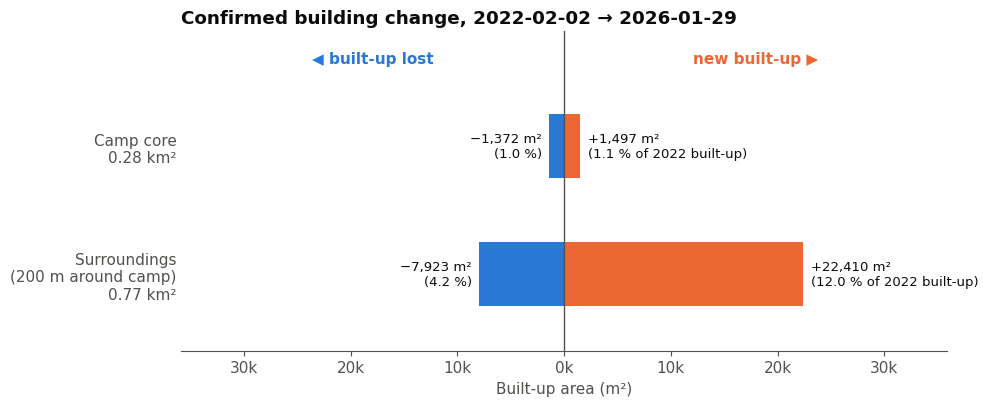

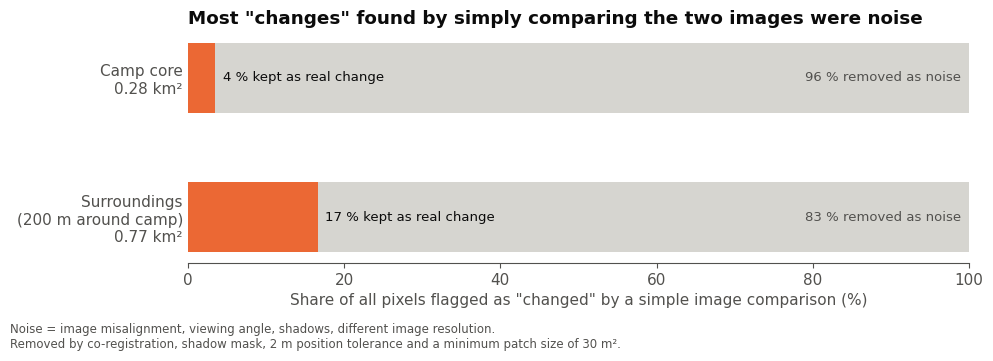

In [20]:
# ---- Clearer result charts ----
NEW_C, LOST_C, NOISE_C = '#eb6834', '#2a78d6', '#d6d5d0'     # orange = new, blue = lost, grey = noise
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': INK2, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2})

NICE = {'camp': 'Camp core', 'ring': 'Surroundings\n(200 m around camp)', 'control': 'Control town'}
rows_ = []
for k in masks:
    s = stats.loc[AREA_NAMES[k]]
    rows_.append({'key': k, 'label': f"{NICE.get(k, k)}\n{s['area_m2'] / 1e6:.2f} km²",
                  'b0': s[f'built_{first}_m2'], 'b1': s[f'built_{last}_m2'],
                  'p0': s[f'built_{first}_pct'], 'p1': s[f'built_{last}_pct'],
                  'new': s['v2_new_m2'], 'lost': s['v2_lost_m2'],
                  'v1': s['v1_new_m2'] + s['v1_lost_m2']})
R = pd.DataFrame(rows_)
y = np.arange(len(R))[::-1]
fmt = lambda v: f'{v:,.0f} m²'
def clean(ax):
    ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='y', length=0)

# 1) MAIN RESULT: confirmed new vs lost built-up
fig, ax = plt.subplots(figsize=(10, 1.6 + 1.3 * len(R)))
ax.barh(y, R['new'], 0.5, color=NEW_C)
ax.barh(y, -R['lost'], 0.5, color=LOST_C)
lim = max(R['new'].max(), R['lost'].max()) * 1.6
for yi, (_, r) in zip(y, R.iterrows()):
    ax.text(r['new'] + lim * 0.02, yi, f"+{fmt(r['new'])}\n({100 * r['new'] / r['b0']:.1f} % of 2022 built-up)",
            va='center', ha='left', fontsize=9.5, color=INK)
    ax.text(-r['lost'] - lim * 0.02, yi, f"−{fmt(r['lost'])}\n({100 * r['lost'] / r['b0']:.1f} %)",
            va='center', ha='right', fontsize=9.5, color=INK)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlim(-lim, lim); ax.set_yticks(y); ax.set_yticklabels(R['label'])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{abs(v) / 1000:.0f}k'))
ax.set_xlabel('Built-up area (m²)')
ax.text(-lim * 0.5, len(R) - 0.35, '◀ built-up lost', color=LOST_C, ha='center', fontsize=11, weight='bold')
ax.text(lim * 0.5, len(R) - 0.35, 'new built-up ▶', color=NEW_C, ha='center', fontsize=11, weight='bold')
ax.set_ylim(-0.6, len(R) - 0.1)
ax.set_title(f'Confirmed building change, {first} → {last}', loc='left', weight='bold', color=INK)
clean(ax); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/03a_confirmed_change.png', dpi=200); plt.show()

# # 2) BUILT-UP SHARE: before -> after (dumbbell)
# fig, ax = plt.subplots(figsize=(10, 1.6 + 1.1 * len(R)))
# for yi, (_, r) in zip(y, R.iterrows()):
#     ax.plot([r['p0'], r['p1']], [yi, yi], color='#b9b8b2', lw=3, zorder=1)
#     ax.scatter(r['p0'], yi, s=110, color='#8f8e88', zorder=2)
#     ax.scatter(r['p1'], yi, s=110, color=NEW_C, zorder=2)
#     ax.text(r['p0'], yi + 0.22, f"{first[:4]}: {r['p0']:.1f} %", ha='center', fontsize=9.5, color=INK2)
#     ax.text(r['p1'], yi - 0.32, f"{last[:4]}: {r['p1']:.1f} %", ha='center', fontsize=9.5, color=INK)
# ax.set_yticks(y); ax.set_yticklabels(R['label']); ax.set_ylim(-0.7, len(R) - 0.3)
# ax.set_xlim(0, max(R[['p0', 'p1']].max()) * 1.2); ax.set_xlabel('Share of the area covered by buildings (%)')
# ax.set_title('How much of each area is covered by buildings', loc='left', weight='bold', color=INK)
# clean(ax); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/03b_built_share.png', dpi=200); plt.show()

# 3) METHOD: how much of the simple comparison was noise
fig, ax = plt.subplots(figsize=(10, 1.6 + 1.0 * len(R)))
for yi, (_, r) in zip(y, R.iterrows()):
    kept = 100 * (r['new'] + r['lost']) / max(r['v1'], 1)
    ax.barh(yi, kept, 0.5, color=NEW_C)
    ax.barh(yi, 100 - kept, 0.5, left=kept, color=NOISE_C)
    ax.text(kept + 1, yi, f'{kept:.0f} % kept as real change', va='center', ha='left', fontsize=9.5, color=INK)
    ax.text(99, yi, f'{100 - kept:.0f} % removed as noise', va='center', ha='right', fontsize=9.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(R['label']); ax.set_xlim(0, 100)
ax.set_xlabel('Share of all pixels flagged as "changed" by a simple image comparison (%)')
ax.set_title('Most "changes" found by simply comparing the two images were noise', loc='left', weight='bold', color=INK)
clean(ax); plt.tight_layout(rect=(0, 0.08, 1, 1))
fig.text(0.01, 0.015, 'Noise = image misalignment, viewing angle, shadows, different image resolution.\n'
         'Removed by co-registration, shadow mask, 2 m position tolerance and a minimum patch size of 30 m².',
         fontsize=8.5, color=INK2)
plt.savefig(f'{OUT_DIR}/03c_noise_removed.png', dpi=200); plt.show()

## 11. Change map

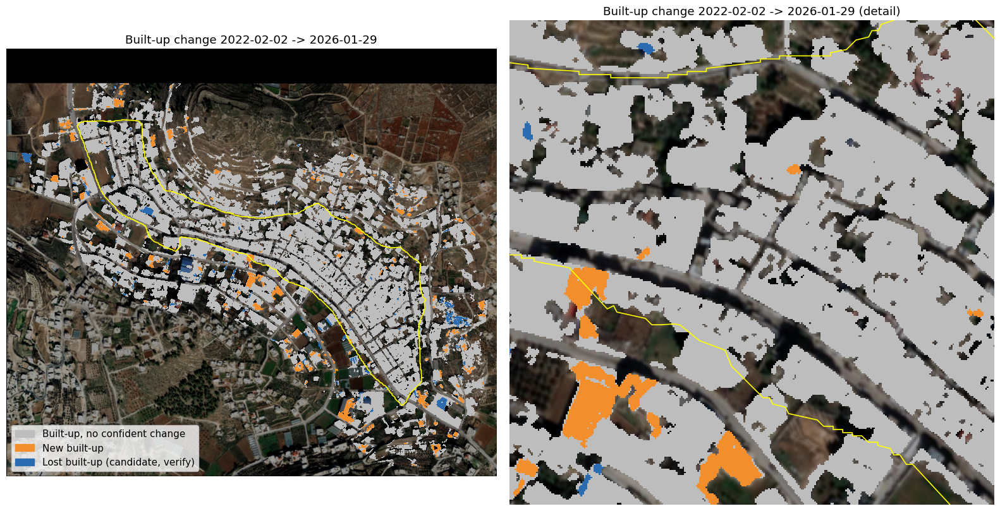

GeoTIFF: 0 = not built, 1 = built (no confident change), 2 = new, 3 = lost candidate
93 lost-candidate patches saved to lost_candidates.gpkg (largest first)


In [21]:
ccmap = ListedColormap(['#00000000', '#bdbdbd', '#f28e2b', '#2b6cb0'])
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, zoom in zip(axes, [False, True]):
    show_rgb(ax, imgs[last], f'Built-up change {first} -> {last}' + (' (detail)' if zoom else ''), dim=0.6, zoom=zoom)
    ax.imshow(np.ma.masked_where(change == 255, change), cmap=ccmap, vmin=-0.5, vmax=3.5,
              extent=EXTENT, interpolation='nearest')
axes[0].legend(handles=[Patch(color='#bdbdbd', label='Built-up, no confident change'),
                        Patch(color='#f28e2b', label='New built-up'),
                        Patch(color='#2b6cb0', label='Lost built-up (candidate, verify)')], loc='lower left')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/04_change_map_v2.png', dpi=200); plt.show()

with rasterio.open(f'{OUT_DIR}/change_v2_{first}_{last}.tif', 'w', driver='GTiff', height=H, width=W, count=1,
                   dtype='uint8', crs=TARGET_CRS, transform=GT, nodata=255, compress='deflate') as dst:
    dst.write(change, 1)
print('GeoTIFF: 0 = not built, 1 = built (no confident change), 2 = new, 3 = lost candidate')

# Lost candidates as polygons with an ID -> check each one in QGIS
lab_lost, n_lost = ndimage.label(lost)
lost_polys = [{'id': int(v), 'area_m2': float((lab_lost == v).sum() * PIX), 'geometry': shape(g)}
              for g, v in shapes(lab_lost.astype('int32'), mask=lost, transform=GT) if v > 0]
if lost_polys:
    lp = gpd.GeoDataFrame(lost_polys, crs=TARGET_CRS).dissolve(by='id', aggfunc='first').reset_index()
    lp['in_camp'] = lp.intersects(camp_geom)
    lp.sort_values('area_m2', ascending=False).to_file(f'{OUT_DIR}/lost_candidates.gpkg', driver='GPKG')
    print(f'{len(lp)} lost-candidate patches saved to lost_candidates.gpkg (largest first)')

In [22]:
# New-built candidates as polygons with an ID -> check each one in QGIS
lab_new, n_new = ndimage.label(new)
new_polys = [{'id': int(v), 'area_m2': float((lab_new == v).sum() * PIX), 'geometry': shape(g)}
             for g, v in shapes(lab_new.astype('int32'), mask=new, transform=GT) if v > 0]
npd = gpd.GeoDataFrame(new_polys, crs=TARGET_CRS).dissolve(by='id', aggfunc='first').reset_index()
npd['in_camp'] = npd.intersects(camp_geom)
npd = npd.sort_values('area_m2', ascending=False)
npd.to_file(f'{OUT_DIR}/new_candidates.gpkg', driver='GPKG')
print(f'{len(npd)} new-candidate patches saved to new_candidates.gpkg (largest first)')
print(f"inside camp: {npd['in_camp'].sum()}, outside: {(~npd['in_camp']).sum()}")
display(npd[['id', 'area_m2', 'in_camp']].head(15).round(1))

166 new-candidate patches saved to new_candidates.gpkg (largest first)
inside camp: 20, outside: 146


,id,area_m2,in_camp
148,149,1824.9,False
92,93,1261.2,False
143,144,891.2,False
95,96,746.1,False
58,59,707.8,False
5,6,636.3,False
11,12,582.4,False
131,132,513.0,False
160,161,494.3,False
13,14,482.9,False


## 12. 50 m grid summary

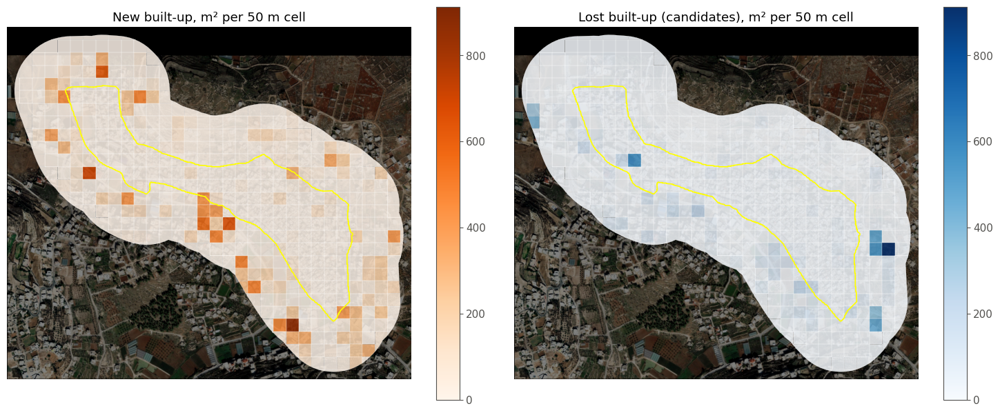

In [23]:
rr, cc = np.indices((H, W))
gx = ((cc * RES) // GRID_M).astype(int); gy = ((rr * RES) // GRID_M).astype(int)
ny, nx = gy.max() + 1, gx.max() + 1
def agg(m):
    a = np.zeros((ny, nx)); np.add.at(a, (gy[m], gx[m]), 1); return a * PIX
new_a, lost_a = agg(new), agg(lost)
net_a = agg(b1 & common) - agg(b0 & common)

cells = []
for j in range(ny):
    for i in range(nx):
        x0 = minx + i * GRID_M; y1 = maxy - j * GRID_M
        g = box(x0, y1 - GRID_M, x0 + GRID_M, y1)
        if g.intersects(buffer_geom):
            cells.append({'new_m2': new_a[j, i], 'lost_m2': lost_a[j, i], 'net_m2': net_a[j, i],
                          'in_camp': g.intersects(camp_geom), 'geometry': g.intersection(buffer_geom)})
grid = gpd.GeoDataFrame(cells, crs=TARGET_CRS)
grid.to_file(f'{OUT_DIR}/grid_{GRID_M}m_change_v2.gpkg', driver='GPKG')

vmax = max(grid['new_m2'].max(), grid['lost_m2'].max(), 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, col, cm, t in [(axes[0], 'new_m2', 'Oranges', 'New built-up'), (axes[1], 'lost_m2', 'Blues', 'Lost built-up (candidates)')]:
    show_rgb(ax, imgs[last], f'{t}, m² per {GRID_M} m cell', dim=0.5)
    grid.plot(column=col, cmap=cm, ax=ax, alpha=0.85, legend=True, vmin=0, vmax=vmax, edgecolor='white', linewidth=0.2)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/05_grid_change_v2.png', dpi=200); plt.show()

## 13. Before / after figure

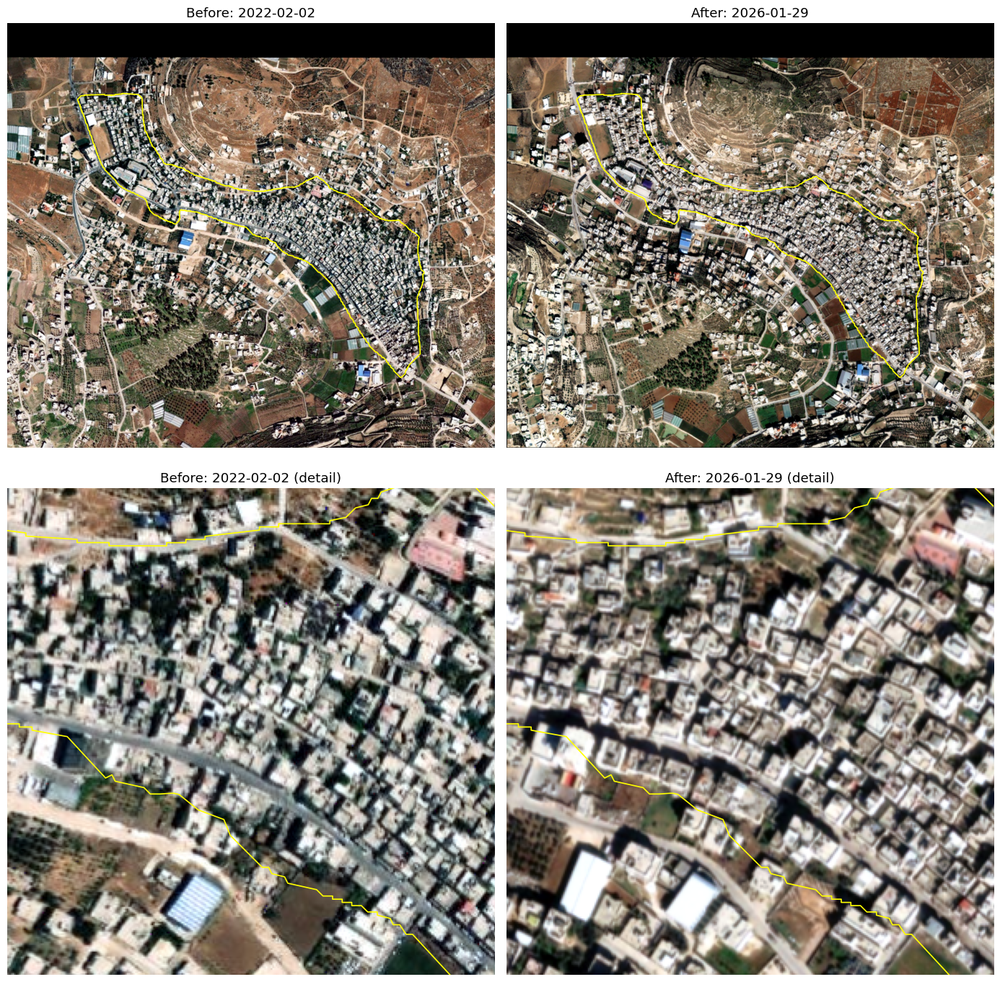

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for i, d in enumerate([first, last]):
    show_rgb(axes[0, i], imgs[d], ('Before: ' if i == 0 else 'After: ') + d)
    show_rgb(axes[1, i], imgs[d], ('Before: ' if i == 0 else 'After: ') + d + ' (detail)', zoom=True)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/06_before_after.png', dpi=200); plt.show()

## 14. Accuracy check – sample points and image chips
`N_CHECK` random points are drawn from each map class. For every point the chips show the **same spot on both dates** (red circle, ~2 m radius). Look at each pair and decide whether the map class is right.

- **new**: was there no building before and a building after?
- **lost**: was there a building before and none after?
- **built (no change)**: a building/paved surface on both dates?
- **not built**: no building on either date?

Write the IDs of the **wrong** points into `WRONG_IDS` in the next cell.

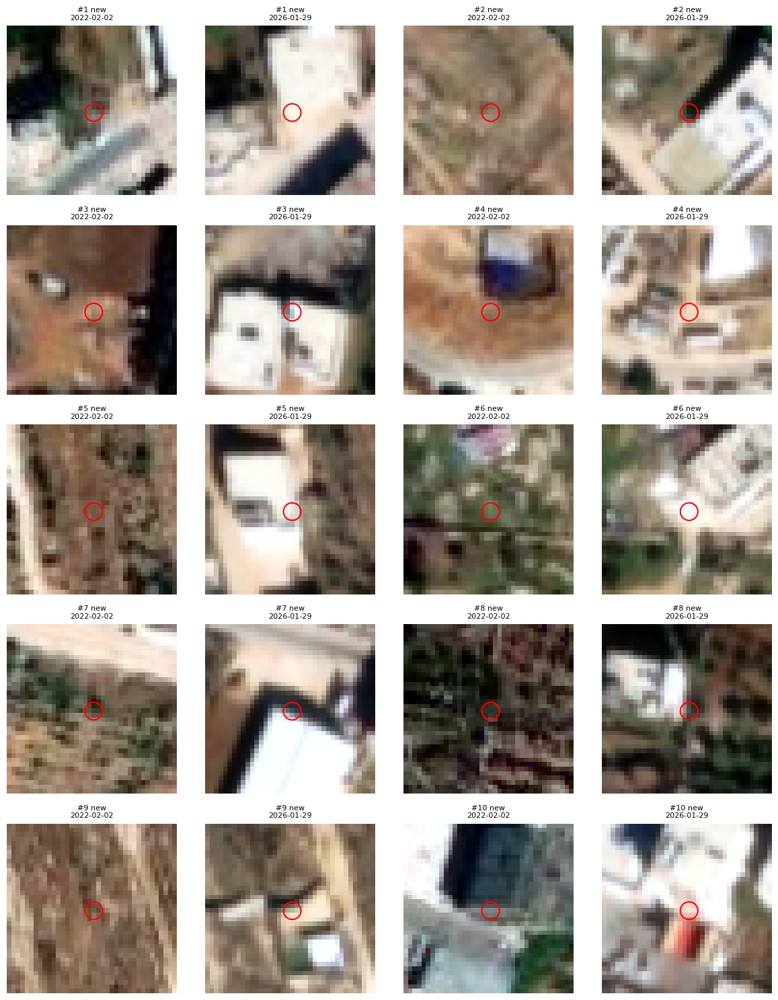

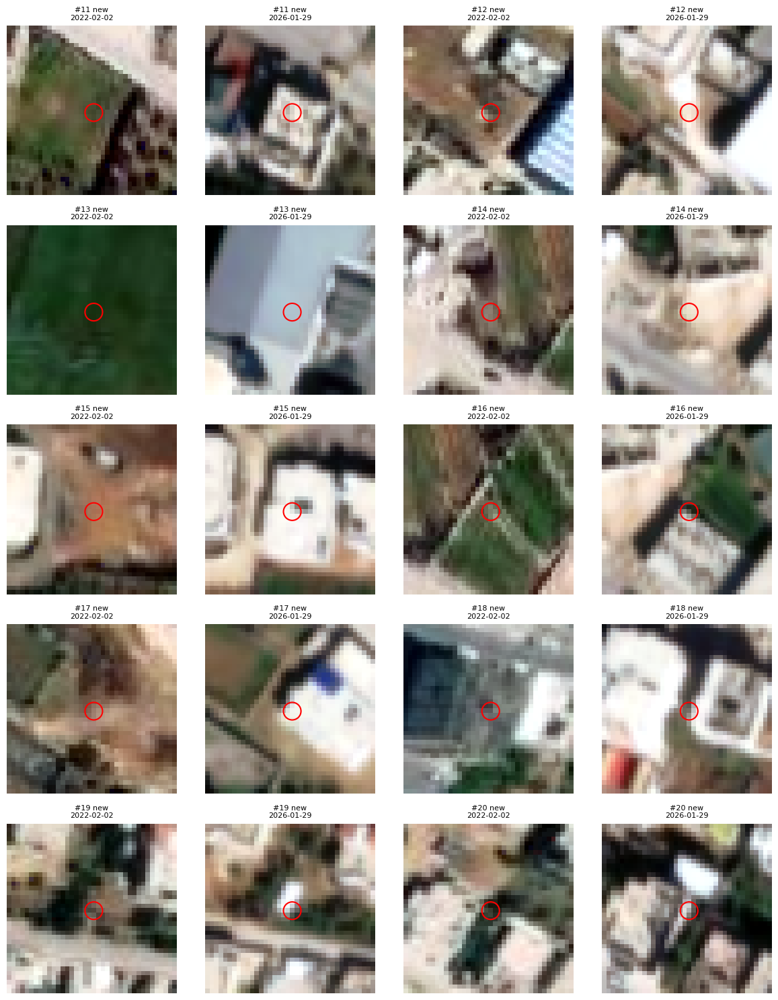

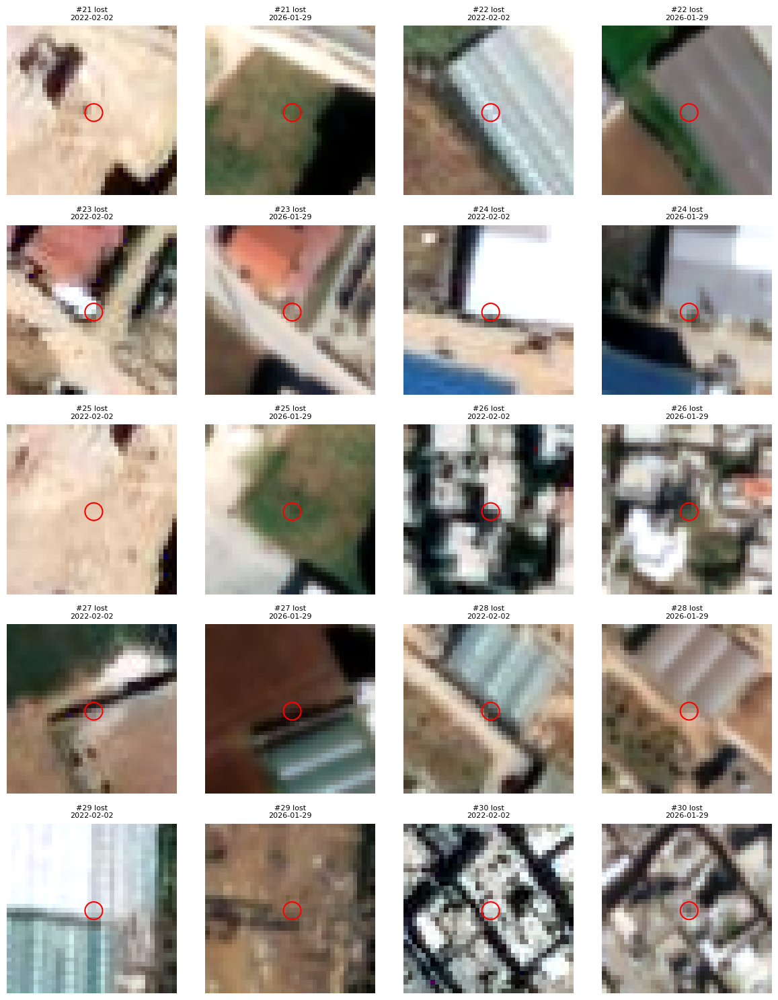

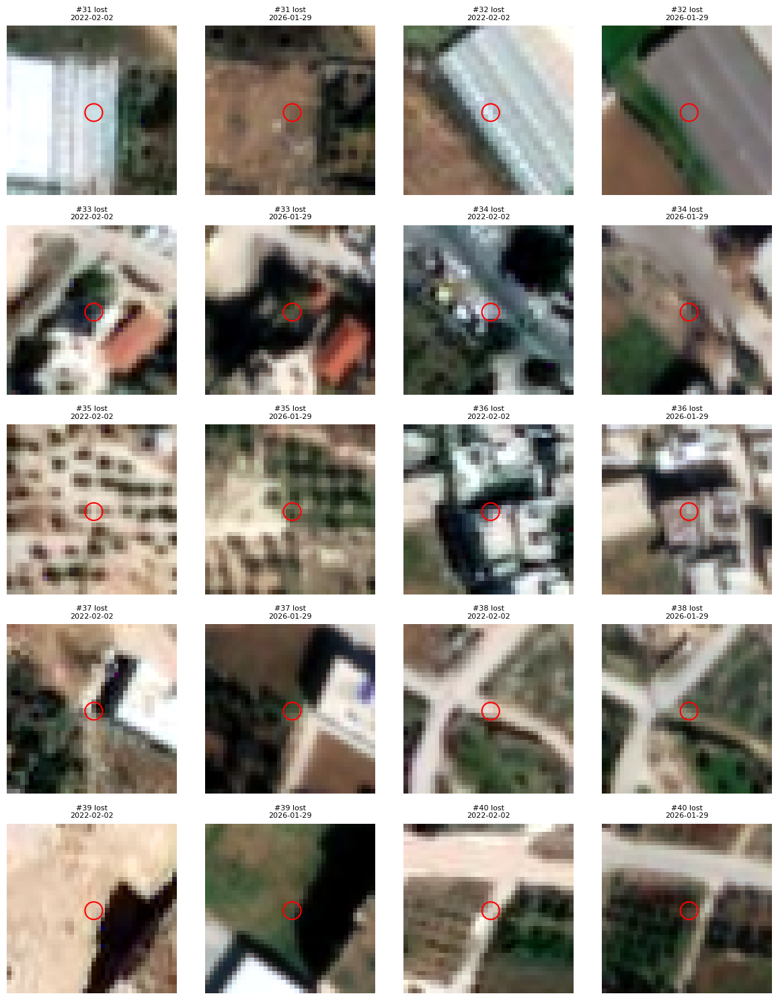

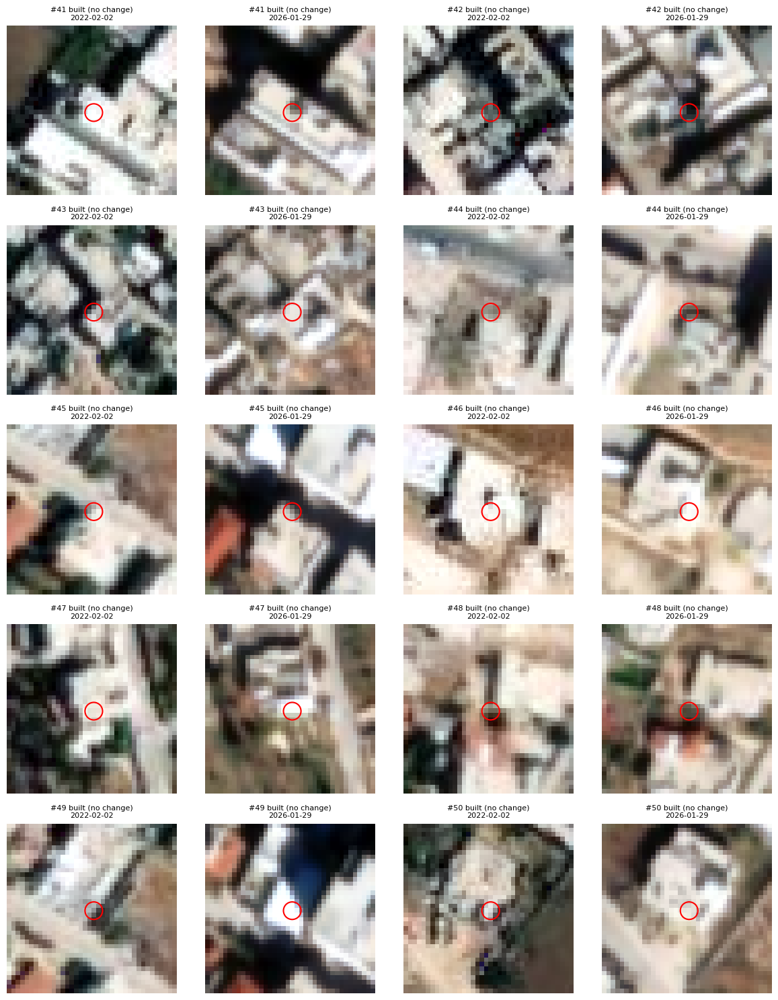

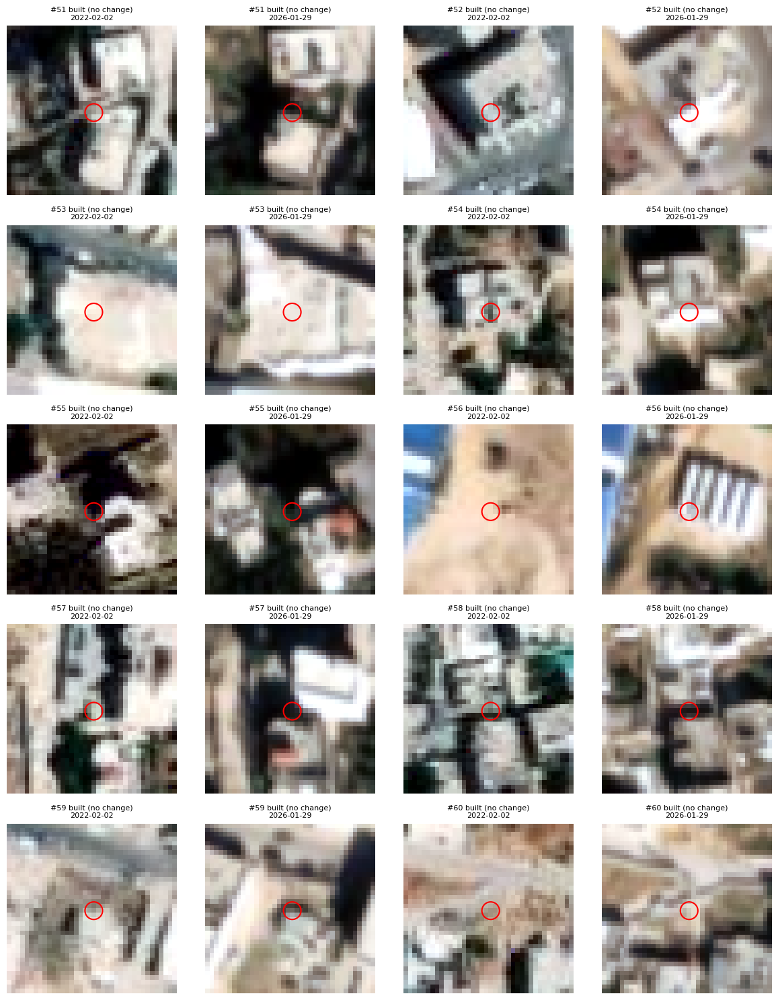

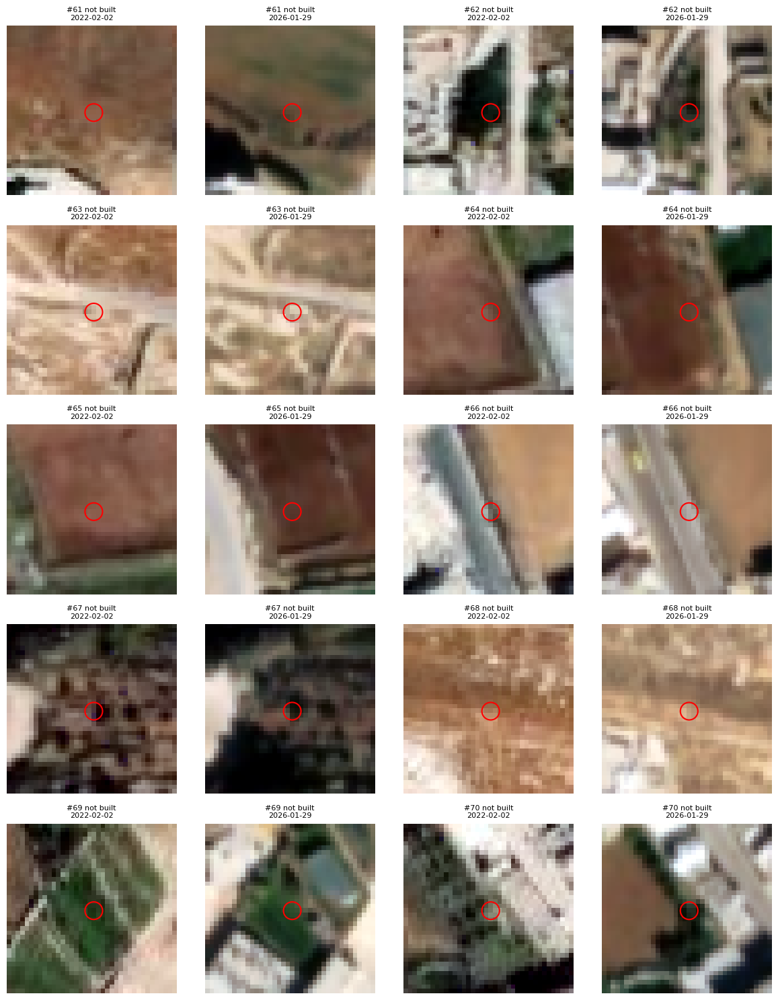

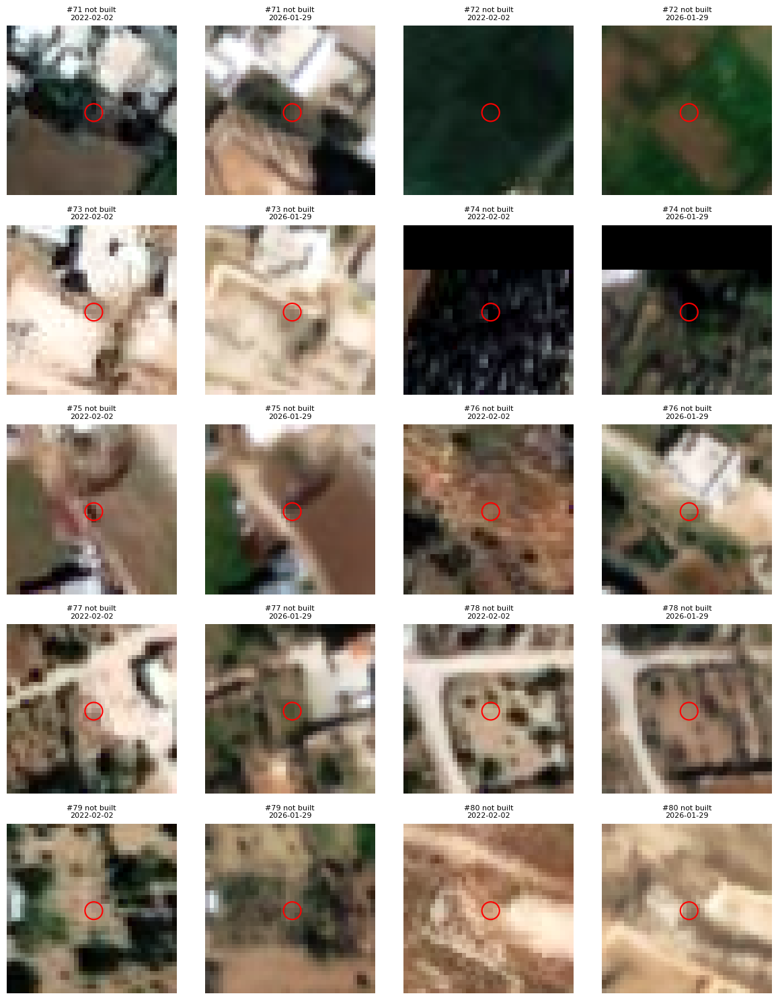

In [25]:
CLASS_NAMES = {2: 'new', 3: 'lost', 1: 'built (no change)', 0: 'not built'}
rng = np.random.default_rng(1)
pts = []
for code_, name in CLASS_NAMES.items():
    rws, cls = np.where(change == code_)
    if len(rws) == 0:
        continue
    for k in rng.choice(len(rws), min(N_CHECK, len(rws)), replace=False):
        pts.append({'map_class': name, 'row': rws[k], 'col': cls[k],
                    'geometry': Point(minx + (cls[k] + 0.5) * RES, maxy - (rws[k] + 0.5) * RES)})
check = gpd.GeoDataFrame(pts, crs=TARGET_CRS)
check.insert(0, 'id', range(1, len(check) + 1))
check.drop(columns=['row', 'col']).to_file(f'{OUT_DIR}/check_points.gpkg', driver='GPKG')

half = int(CHIP_M / RES)
per_page = 10
for p0 in range(0, len(check), per_page):
    page = check.iloc[p0:p0 + per_page]
    fig, axes = plt.subplots(5, 4, figsize=(12, 15))
    for ax in axes.ravel():
        ax.set_axis_off()
    for j, (_, r) in enumerate(page.iterrows()):
        rr0, cc0 = int(r.row), int(r.col)
        for k, d in enumerate([first, last]):
            ax = axes[j // 2, (j % 2) * 2 + k]
            chip = imgs[d][max(rr0 - half, 0):rr0 + half, max(cc0 - half, 0):cc0 + half]
            ax.imshow(np.nan_to_num(chip))
            ax.add_patch(Circle((min(cc0, half), min(rr0, half)), 2 / RES, fill=False, color='red', lw=1.5))
            ax.set_title(f'#{r.id} {r.map_class}\n{d}', fontsize=8)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/check_page_{p0 // per_page + 1:02d}.png', dpi=130); plt.show()

In [26]:
WRONG_IDS = [10,12,14,16,24,25,27,28,29,30,35,36,37,38,39,40,56,76]          # <- fill in after looking at the chips, e.g. [3, 17, 22]

check['correct'] = ~check['id'].isin(WRONG_IDS)
acc = check.groupby('map_class')['correct'].agg(['count', 'sum'])
acc['accuracy_%'] = 100 * acc['sum'] / acc['count']
acc = acc.rename(columns={'count': 'checked', 'sum': 'correct'})
display(acc.round(1))
print(f"Overall: {100 * check['correct'].mean():.1f} % of {len(check)} points correct")
acc.to_csv(f'{OUT_DIR}/accuracy_check.csv')

,checked,correct,accuracy_%
map_class,,,
built (no change),20,19,95.0
lost,20,8,40.0
new,20,16,80.0
not built,20,19,95.0


Overall: 77.5 % of 80 points correct


In [28]:
# === What would a 10 m sensor see? Aggregate my 1 m change map to 10 m cells ===
import numpy as np, rasterio
from scipy import ndimage
with rasterio.open('/content/outputs_v2/change_v2_2022-02-02_2026-01-29.tif') as src:
    a = src.read(1); px = src.res[0]          # 0 none, 1 stable built, 2 new, 3 lost, 255 outside
new, k = (a == 2), round(10 / px)
H, W = (a.shape[0] // k) * k, (a.shape[1] // k) * k
n = new[:H, :W].reshape(H//k, k, W//k, k).sum((1, 3))
v = (a != 255)[:H, :W].reshape(H//k, k, W//k, k).sum((1, 3))
frac = np.where(v > 0, n / np.maximum(v, 1), 0)
for t in (0.5, 0.25):
    print(f'new area in 10 m cells >= {t:.0%} new: {n[frac >= t].sum() / n.sum():.0%}')
lab, nl = ndimage.label(new)
sizes = ndimage.sum(new, lab, range(1, nl + 1)) * px * px
print(f'patches smaller than one 10 m pixel: {(sizes < 100).mean():.0%} of {nl}, median {np.median(sizes):.0f} m²')

new area in 10 m cells >= 50% new: 52%
new area in 10 m cells >= 25% new: 83%
patches smaller than one 10 m pixel: 64% of 166, median 65 m²


## 15. Download all results

In [ ]:
import shutil
shutil.make_archive('/content/outputs_v2', 'zip', OUT_DIR)
from google.colab import files
files.download('/content/outputs_v2.zip')

## Tuning tips
| Problem you see | Setting to change |
|---|---|
| Still many orange/blue slivers along building edges | increase `TOL_M` (2 → 3) |
| Small real buildings disappear from the change map | decrease `MIN_CHANGE_M2` (30 → 20) or `CHANGE_OPEN_M` (1.5 → 1.0) |
| Greenhouses / fields counted as built-up | remove their class from `BUILT_CLUSTERS`, increase `N_CLUSTERS`, or use `TRAIN_FILE` |
| Shadows flagged as lost | increase `SHADOW_PCT` (8 → 12) |
| Real changes missing | set `SPECTRAL_CHECK = False` |

## Limitations to state in the report
1. **Built-up area ≠ number of buildings**; vertical growth (extra floors) is invisible from above.
2. Remaining classification errors: bright limestone, levelled land, greenhouses, shadows.
3. The noise filters make the map **conservative**: small extensions (< `MIN_CHANGE_M2`) are not counted.
4. **Lost ≠ demolished**: every lost candidate must be checked against high-resolution imagery and documented demolition records (e.g. OCHA oPt).
5. Report the image acquisition dates, sources and the **accuracy check result**.
6. Imagery shows *that* something changed, not *who* caused it or *why*.